In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task4_motion_estimation"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load video
video_path = DATASET_DIR / "motion_video.mp4"

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise FileNotFoundError("Could not open motion_video.mp4")

# Video information
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = total_frames / fps if fps > 0 else 0

print("Video loaded successfully!")
print("FPS:", fps)
print("Total Frames:", total_frames)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")


Video loaded successfully!
FPS: 29.814156538465166
Total Frames: 527
Resolution: 478 x 850
Duration: 17.68 seconds


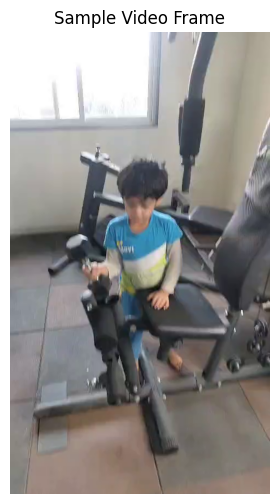

In [2]:
ret, frame = cap.read()

if ret:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Sample Video Frame")
    plt.axis("off")
    plt.show()
else:
    print("Could not read video frame.")

cap.release()

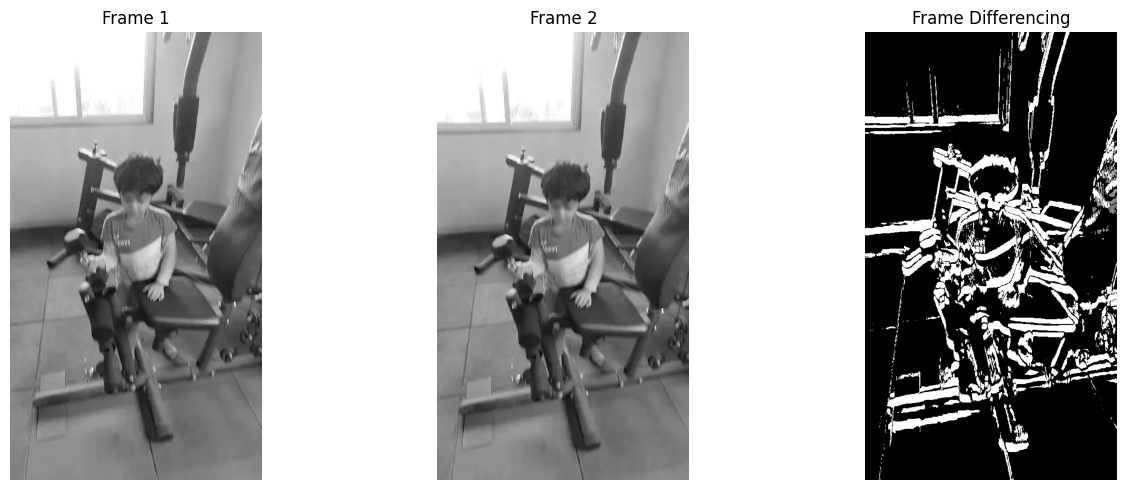

In [4]:
# Reopen video
cap = cv2.VideoCapture(str(video_path))

# Read two consecutive frames
ret, frame1 = cap.read()
ret, frame2 = cap.read()

if not ret:
    raise ValueError("Could not read consecutive video frames.")

# Convert frames to grayscale
gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

# Calculate absolute difference
frame_diff = cv2.absdiff(gray1, gray2)

# Apply threshold
_, motion_mask = cv2.threshold(
    frame_diff, 25, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Frame 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gray2, cmap="gray")
plt.title("Frame 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(motion_mask, cmap="gray")
plt.title("Frame Differencing")
plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
cv2.imwrite(
    str(OUTPUT_DIR / "frame_differencing.png"),
    motion_mask
)

print("Frame differencing result saved!")

Frame differencing result saved!


In [6]:
# Open video again
cap = cv2.VideoCapture(str(video_path))

# Create GMM background subtractor
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=50,
    detectShadows=True
)

# Process video frames
gmm_frames = []

while True:
    ret, frame = cap.read()

    if not ret:
        break

    foreground_mask = back_sub.apply(frame)
    gmm_frames.append(foreground_mask)

cap.release()

print("GMM processing completed!")
print("Frames processed:", len(gmm_frames))

GMM processing completed!
Frames processed: 527


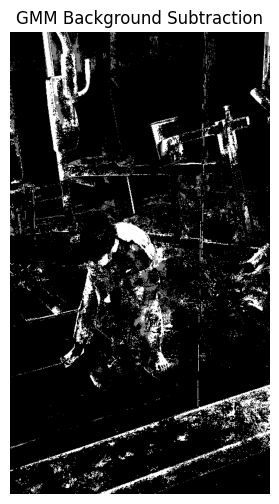

GMM output saved successfully!


In [7]:
# Display a sample GMM foreground mask
sample_mask = gmm_frames[len(gmm_frames) // 2]

plt.figure(figsize=(10, 6))
plt.imshow(sample_mask, cmap="gray")
plt.title("GMM Background Subtraction")
plt.axis("off")
plt.show()

# Save output
cv2.imwrite(
    str(OUTPUT_DIR / "gmm_background_subtraction.png"),
    sample_mask
)

print("GMM output saved successfully!")

In [8]:
cap = cv2.VideoCapture(str(video_path))

# Read the first frame
ret, old_frame = cap.read()

# Skip a few frames to capture movement
for _ in range(5):
    ret, new_frame = cap.read()

cap.release()

old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)
new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

# Detect feature points
features = cv2.goodFeaturesToTrack(
    old_gray,
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

print("Feature points detected:", len(features))

Feature points detected: 24


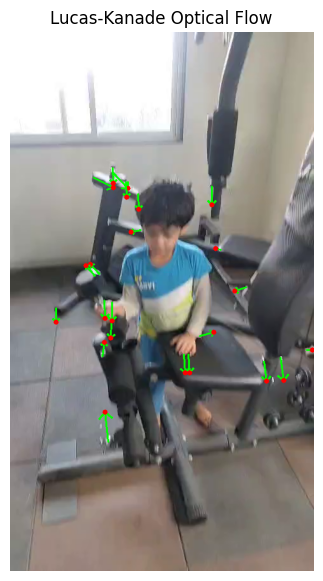

Tracked points: 23
Optical flow output saved successfully!


In [9]:
# Calculate optical flow
next_points, status, error = cv2.calcOpticalFlowPyrLK(
    old_gray,
    new_gray,
    features,
    None,
    winSize=(15, 15),
    maxLevel=2,
    criteria=(
        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
        10,
        0.03
    )
)

# Keep successfully tracked points
good_old = features[status == 1]
good_new = next_points[status == 1]

# Draw motion lines and points
flow_image = old_frame.copy()

for old, new in zip(good_old, good_new):
    x1, y1 = old.ravel().astype(int)
    x2, y2 = new.ravel().astype(int)

    cv2.arrowedLine(
        flow_image, (x1, y1), (x2, y2),
        (0, 255, 0), 2, tipLength=0.3
    )
    cv2.circle(flow_image, (x2, y2), 4, (0, 0, 255), -1)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(flow_image, cv2.COLOR_BGR2RGB))
plt.title("Lucas-Kanade Optical Flow")
plt.axis("off")
plt.show()

# Save output
cv2.imwrite(
    str(OUTPUT_DIR / "lucas_kanade_optical_flow.png"),
    flow_image
)

print("Tracked points:", len(good_new))
print("Optical flow output saved successfully!")

In [12]:
import pandas as pd

In [13]:
comparison = pd.DataFrame({
    "Method": [
        "Frame Differencing",
        "GMM Background Subtraction",
        "Lucas-Kanade Optical Flow"
    ],
    "Technique": [
        "Difference between consecutive frames",
        "Separates foreground from background",
        "Tracks movement of feature points"
    ],
    "Purpose": [
        "Detects changes between frames",
        "Identifies moving foreground objects",
        "Estimates direction and movement"
    ]
})

display(comparison)

comparison.to_csv(
    OUTPUT_DIR / "motion_estimation_comparison.csv",
    index=False
)

print("Comparison CSV saved successfully!")

,Method,Technique,Purpose
0,Frame Differencing,Difference between consecutive frames,Detects changes between frames
1,GMM Background Subtraction,Separates foreground from background,Identifies moving foreground objects
2,Lucas-Kanade Optical Flow,Tracks movement of feature points,Estimates direction and movement


Comparison CSV saved successfully!


In [ ]:
## Observations

1. **Frame Differencing:** Detects changes between consecutive frames. It is simple and effective for identifying motion but can be sensitive to noise and lighting changes.

2. **GMM Background Subtraction:** Separates moving foreground objects from the background by modelling background variations. It is useful for detecting moving objects in video sequences.

3. **Lucas-Kanade Optical Flow:** Tracks selected feature points between frames and estimates their movement. It provides information about the direction and displacement of motion.

## Conclusion

In this experiment, three motion estimation techniques were implemented using OpenCV. Frame differencing detected changes between frames, GMM identified foreground regions, and Lucas-Kanade Optical Flow tracked feature-point movement. Each technique has different advantages and limitations depending on the video and motion conditions.